In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from scipy import stats
from sklearn import metrics
from sklearn.metrics import roc_curve, roc_auc_score, RocCurveDisplay
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

In [3]:
nombres_columnas = ['pregnant','glucose','bp','skin','insulin','bmi','pedigree','age','label']
diabetes = pd.read_csv("./Datasets/diabetes.csv", header=None, names=nombres_columnas)
diabetes = diabetes.iloc[1:]

In [6]:
print(diabetes.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 1 to 768
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   pregnant  768 non-null    object
 1   glucose   768 non-null    object
 2   bp        768 non-null    object
 3   skin      768 non-null    object
 4   insulin   768 non-null    object
 5   bmi       768 non-null    object
 6   pedigree  768 non-null    object
 7   age       768 non-null    object
 8   label     768 non-null    object
dtypes: object(9)
memory usage: 54.1+ KB
None


In [8]:
columnas_caracteristicas = ['pregnant','insulin','bmi','age','glucose','bp','pedigree']
X = diabetes[columnas_caracteristicas] # caracteristicas
y = diabetes.label # Variable target

In [10]:
X2 = sm.add_constant(X).rename(columns={'const':'intercept'})
X2 = X2.apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(y, errors='coerce')

X2 = X2.dropna()
y = y.dropna()
est = sm.OLS(y, X2)
est2 = est.fit()
est2.conf_int(alpha=0.05, cols=None)
print(est2.summary())

                            OLS Regression Results                            
Dep. Variable:                  label   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.297
Method:                 Least Squares   F-statistic:                     47.25
Date:                Tue, 24 Jun 2025   Prob (F-statistic):           1.04e-55
Time:                        16:17:45   Log-Likelihood:                -381.92
No. Observations:                 768   AIC:                             779.8
Df Residuals:                     760   BIC:                             817.0
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.8538      0.085     -9.994      0.0

In [12]:
p_values = est2.pvalues
print(p_values)

intercept    3.513148e-22
pregnant     6.479555e-05
insulin      2.092868e-01
bmi          2.761547e-11
age          9.172958e-02
glucose      7.683739e-29
bp           4.011366e-03
pedigree     1.004392e-03
dtype: float64


In [14]:
caracteristicas = est2.pvalues[est2.pvalues<0.05].index
print(caracteristicas.values)
X_seleccionadas = X2[caracteristicas]

['intercept' 'pregnant' 'bmi' 'glucose' 'bp' 'pedigree']


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X_seleccionadas, y, test_size=0.25, random_state=16)

In [18]:
modelo = LogisticRegression(random_state=16, max_iter=1000)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

In [20]:
matriz_confusion = metrics.confusion_matrix(y_test, y_pred)
matriz_confusion

array([[116,   9],
       [ 26,  41]], dtype=int64)

Text(0.5, 427.9555555555555, 'Prediccion')

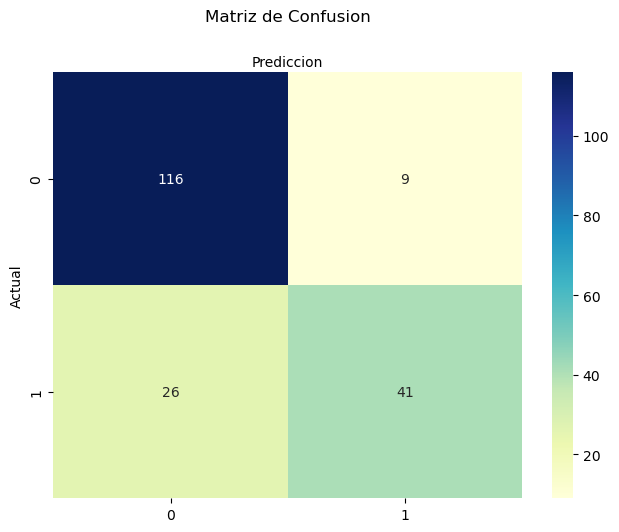

In [28]:
nombres_clases=[0,1]
fig, ax = plt.subplots()
marcas_verificacion = np.arange(len(nombres_clases))
plt.xticks(marcas_verificacion, nombres_clases)
plt.yticks(marcas_verificacion, nombres_clases)

sns.heatmap(pd.DataFrame(matriz_confusion), annot=True, cmap="YlGnBu", fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Matriz de Confusion',y=1.1)
plt.ylabel('Actual')
plt.xlabel('Prediccion')

In [30]:
nombres_target = ['Sin diabetes','Con diabetes']
print(classification_report(y_test, y_pred, target_names=nombres_target))

              precision    recall  f1-score   support

Sin diabetes       0.82      0.93      0.87       125
Con diabetes       0.82      0.61      0.70        67

    accuracy                           0.82       192
   macro avg       0.82      0.77      0.78       192
weighted avg       0.82      0.82      0.81       192



In [34]:
y_pred = y_pred.astype(int)
#(True Positive + True Negative) / Total Predictions
Accuracy =metrics.accuracy_score(y_test, y_pred)
#True Positive / (True Positive + False Positive)
Precision = metrics.precision_score(y_test, y_pred)
#True Positive / (True Positive + False Negative)
Sensitivity_recall = metrics.recall_score(y_test, y_pred)
#True Negative / (True Negative + False Positive)
Specificity = metrics.recall_score(y_test, y_pred, pos_label=0)
#2 * ((Precision * Sensitivity) / (Precision + Sensitivity))
F1_score = metrics.f1_score(y_test, y_pred)
print({"Exactitud":Accuracy,"Precision":Precision,
      "Sensibilidad_recall":Sensitivity_recall,
      "Especificidad":Specificity,"F1_score":F1_score})

{'Exactitud': 0.8177083333333334, 'Precision': 0.82, 'Sensibilidad_recall': 0.6119402985074627, 'Especificidad': 0.928, 'F1_score': 0.7008547008547008}


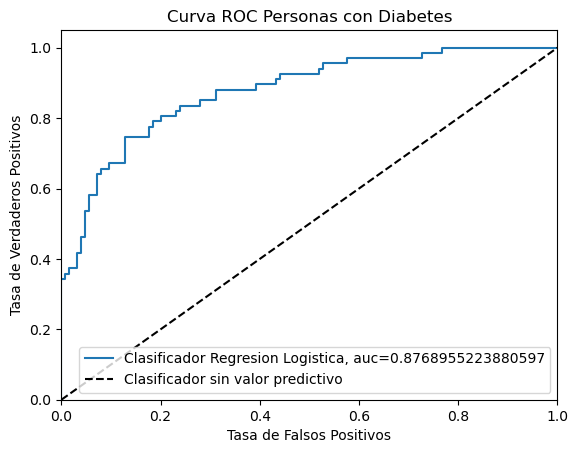

In [36]:
ns_probs = [0 for _ in range(len(y_test))]
y_test = y_test.astype(int)

y_pred_proba = modelo.predict_proba(X_test)[::,1]
ns_fpr, ns_tpr, thresholds = roc_curve(y_test, ns_probs)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

auc = roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="Clasificador Regresion Logistica, auc="+str(auc))
plt.plot([0,1],[0,1], 'k--', label='Clasificador sin valor predictivo')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC Personas con Diabetes')
plt.legend(loc=4)
plt.show()